# ¿Cuánto cuesta no ver la bandera a cuadros? — Notebook Principal (`main.ipynb`)

**Autor:** Borja Bueno Garaigordobil  
**Periodo analizado:** Histórico (1990–2023) y foco de temporada moderna (2023)  
**Repositorio:** Estructura modular `src/` (`data/`, `notebooks/`, `utils/`, `main.ipynb`)

Este cuaderno orquesta de extremo a extremo la síntesis ejecutiva del Análisis Exploratorio de Datos (EDA) apoyándose en el paquete reutilizable [`utils/`](utils/). Para consultar la exploración paso a paso, las pruebas de sensibilidad completas y la auditoría manual de estados, accede a:
- Limpieza y clasificación `statusGeneric`: [`notebooks/00_exploracion_y_limpieza.ipynb`](notebooks/00_exploracion_y_limpieza.ipynb)
- Hipótesis H1 (Fiabilidad histórica): [`notebooks/01_hipotesis_1.ipynb`](notebooks/01_hipotesis_1.ipynb)
- Hipótesis H2 (Accidentes vs. Mecánica): [`notebooks/02_hipotesis_2.ipynb`](notebooks/02_hipotesis_2.ipynb)
- Hipótesis H3 (Concentración y parrilla 2023): [`notebooks/03_hipotesis_3.ipynb`](notebooks/03_hipotesis_3.ipynb)
- Hipótesis H4 (Coste en puntos y factura de taller): [`notebooks/04_hipotesis_4.ipynb`](notebooks/04_hipotesis_4.ipynb)
- Auditorías documentales: [`../docs/informe_statusGeneric.md`](../docs/informe_statusGeneric.md) y [`../docs/informe_retired_statusId31.md`](../docs/informe_retired_statusId31.md)

In [1]:
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import pandas as pd

# Garantizar import de utils/ tanto ejecutando desde src/ como desde la raíz del repo
for candidate in (Path.cwd(), Path.cwd() / "src"):
    if (candidate / "utils").is_dir() and str(candidate) not in sys.path:
        sys.path.insert(0, str(candidate))

warnings.filterwarnings("ignore")

from utils import (
    AZUL_MEC,
    BLANCO_F1,
    GRIS_F1,
    PLATA_F1,
    ROJO_F1,
    cargar_datos_2023,
    cargar_datos_historicos,
    estilizar_ejes_f1,
    evaluar_h1,
    evaluar_h2,
    evaluar_h3,
    evaluar_h4,
    f1_dark_context,
    umbral_criterio,
)

## 1. Carga unificada de datos limpios

In [2]:
hist = cargar_datos_historicos()
datos_23 = cargar_datos_2023()

print(f"Histórico 1990-2023 (coches que salieron): {len(hist):,} registros en {hist['raceId'].nunique()} GPs")
print(f"Temporada 2023: {len(datos_23['results'])} participaciones en {len(datos_23['races'])} GPs")
print(f"Vueltas 2023 (lap_times_23): {len(datos_23['lap_times']):,} registros")

Histórico 1990-2023 (coches que salieron): 13,446 registros en 617 GPs
Temporada 2023: 440 participaciones en 22 GPs
Vueltas 2023 (lap_times_23): 24,386 registros


## 2. H1 — La tasa de abandono mecánico ha caído de forma sostenida (1990–2023)

Media 1990-1999: 30.23%
Media 2020-2023: 6.96% (umbral < 1/3 = 10.08%)
Reducción relativa: -77.0%
Veredicto H1: ✅ CONFIRMADA


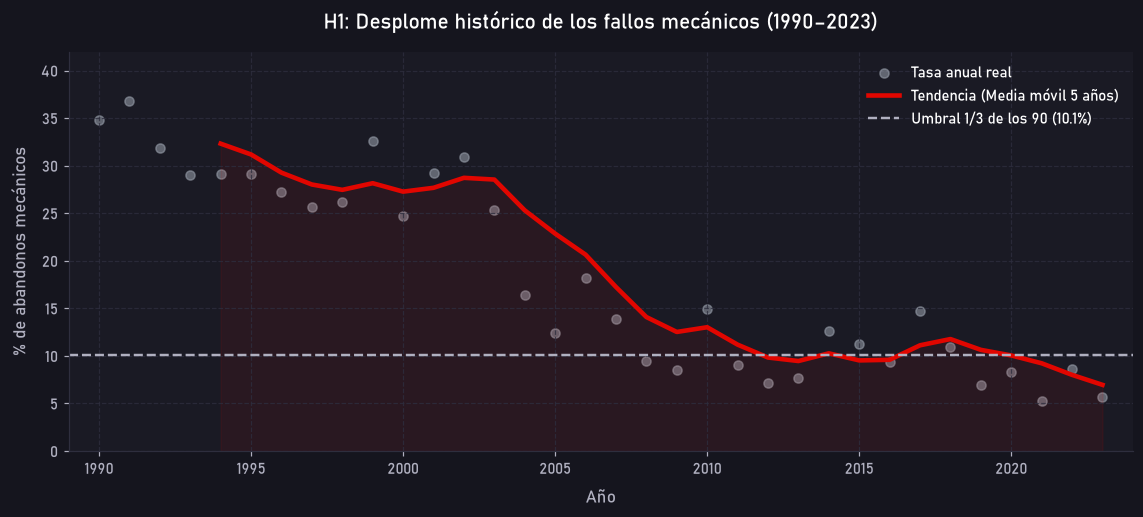

In [3]:
res_h1 = evaluar_h1(hist)
print(f"Media 1990-1999: {res_h1['tasa_1990s']:.2f}%")
print(f"Media 2020-2023: {res_h1['tasa_2020s']:.2f}% (umbral < 1/3 = {res_h1['tasa_1990s']/3:.2f}%)")
print(f"Reducción relativa: -{res_h1['reduccion_pct']:.1f}%")
print(f"Veredicto H1: {'✅ CONFIRMADA' if res_h1['confirmada'] else '⚪ NO SE CONFIRMA'}")

with f1_dark_context():
    fig, ax = plt.subplots(figsize=(10.5, 4.8))
    serie = res_h1["serie_mecanicos"]
    mm5 = res_h1["media_movil_5y"]

    ax.scatter(serie.index, serie.values, color=GRIS_F1, alpha=0.55, s=36, label="Tasa anual real")
    ax.plot(mm5.index, mm5.values, color=ROJO_F1, linewidth=3.0, label="Tendencia (Media móvil 5 años)")
    ax.fill_between(mm5.index, mm5.values, color=ROJO_F1, alpha=0.08)
    umbral_criterio(ax, res_h1["tasa_1990s"] / 3, f"Umbral 1/3 de los 90 ({res_h1['tasa_1990s']/3:.1f}%)")

    estilizar_ejes_f1(ax, "H1: Desplome histórico de los fallos mecánicos (1990–2023)", "Año", "% de abandonos mecánicos")
    ax.set_xlim(1989, 2024)
    ax.set_ylim(0, 42)
    legend = ax.legend(loc="upper right")
    for t in legend.get_texts():
        t.set_color(BLANCO_F1)
    plt.tight_layout()
    plt.show()

## 3. H2 — ¿Dominan ya los accidentes frente a los fallos mecánicos?

Cuota media A/(A+M) 1990-1999: 37.09%
Cuota media A/(A+M) 2020-2023: 52.60%
Temporadas 2020-2023 > 50%: 2/4 (requeridas >= 3)
Veredicto H2: ⚪ NO SE CONFIRMA


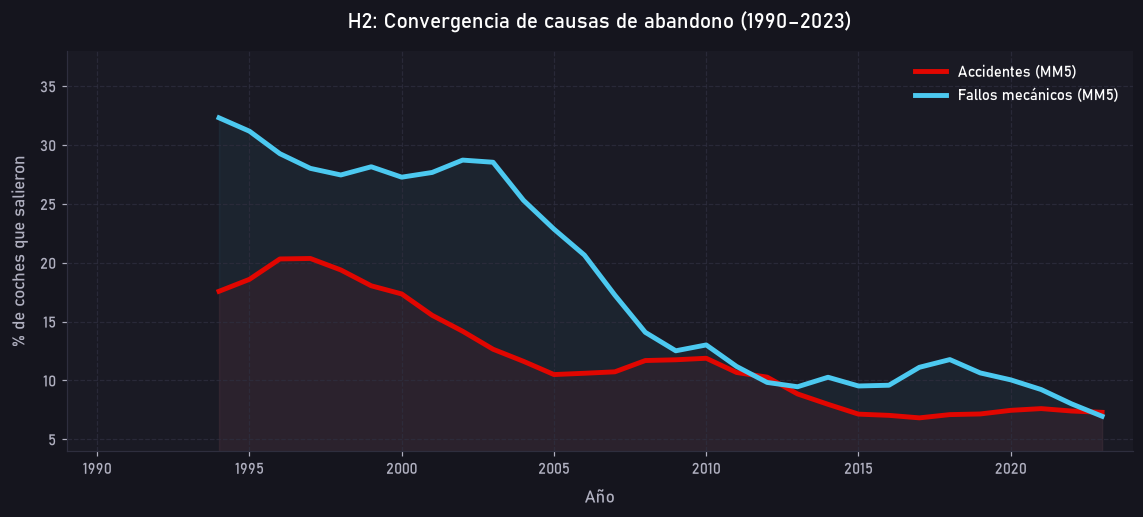

In [4]:
res_h2 = evaluar_h2(hist)
print(f"Cuota media A/(A+M) 1990-1999: {res_h2['medias_cuota']['1990-1999']:.2%}")
print(f"Cuota media A/(A+M) 2020-2023: {res_h2['medias_cuota']['2020-2023']:.2%}")
print(f"Temporadas 2020-2023 > 50%: {res_h2['temporadas_sobre_50']}/4 (requeridas >= 3)")
print(f"Veredicto H2: {'✅ CONFIRMADA' if res_h2['confirmada'] else '⚪ NO SE CONFIRMA'}")

with f1_dark_context():
    fig, ax = plt.subplots(figsize=(10.5, 4.8))
    acc_mm = res_h2["serie_accidentes"].rolling(5).mean()
    mec_mm = res_h2["serie_mecanicos"].rolling(5).mean()

    ax.plot(acc_mm.index, acc_mm.values, color=ROJO_F1, linewidth=3.2, label="Accidentes (MM5)")
    ax.plot(mec_mm.index, mec_mm.values, color=AZUL_MEC, linewidth=3.2, label="Fallos mecánicos (MM5)")
    ax.fill_between(acc_mm.index, acc_mm.values, color=ROJO_F1, alpha=0.08)
    ax.fill_between(mec_mm.index, mec_mm.values, color=AZUL_MEC, alpha=0.06)

    estilizar_ejes_f1(ax, "H2: Convergencia de causas de abandono (1990–2023)", "Año", "% de coches que salieron")
    ax.set_xlim(1989, 2024)
    ax.set_ylim(4, 38)
    legend = ax.legend(loc="upper right")
    for t in legend.get_texts():
        t.set_color(BLANCO_F1)
    plt.tight_layout()
    plt.show()

## 4. H3 — Concentración por equipos y gradiente de parrilla (Temporada 2023)

Total accidentes 2023: 33 (media 3.3 por equipo)
Top-3 equipos: 48.5% | Chi2 p-value: 0.9661
Gradiente parrilla: 1.52x (Delantera 5.94% vs Trasera 9.05%)
Veredicto H3: ⚪ NO SE CONFIRMA


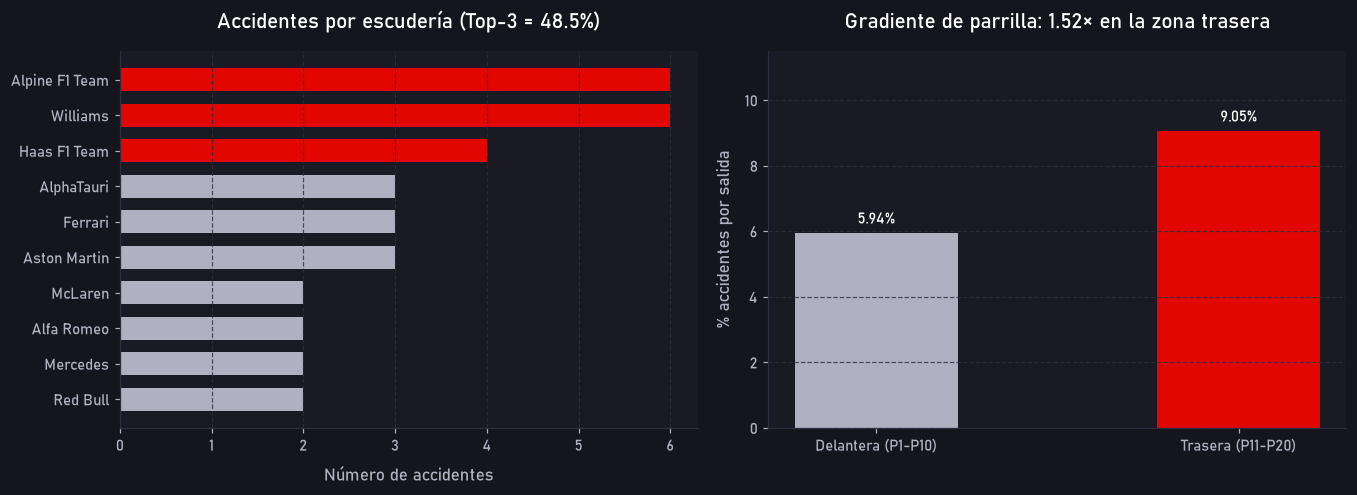

In [5]:
res_h3 = evaluar_h3(datos_23["results"], datos_23["constructors"])
print(f"Total accidentes 2023: {res_h3['total_accidentes']} (media {res_h3['media_por_equipo']:.1f} por equipo)")
print(f"Top-3 equipos: {res_h3['top3_pct']:.1f}% | Chi2 p-value: {res_h3['p_value_chi2']:.4f}")
print(
    f"Gradiente parrilla: {res_h3['gradiente_parrilla']:.2f}x "
    f"(Delantera {res_h3['tasa_delantera_pct']:.2f}% vs Trasera {res_h3['tasa_trasera_pct']:.2f}%)"
)
print(f"Veredicto H3: {'✅ CONFIRMADA' if res_h3['confirmada'] else '⚪ NO SE CONFIRMA'}")

with f1_dark_context():
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.6))

    eq = res_h3["accidentes_por_equipo"]
    col_eq = [ROJO_F1] * 3 + [PLATA_F1] * (len(eq) - 3)
    ax1.barh(eq.index[::-1], eq.values[::-1], color=col_eq[::-1], height=0.65)
    estilizar_ejes_f1(ax1, "Accidentes por escudería (Top-3 = 48.5%)", "Número de accidentes", grid_axis="x")

    mitad_labels = ["Delantera (P1-P10)", "Trasera (P11-P20)"]
    tasas_mitad = [res_h3["tasa_delantera_pct"], res_h3["tasa_trasera_pct"]]
    bars = ax2.bar(mitad_labels, tasas_mitad, color=[PLATA_F1, ROJO_F1], width=0.45)
    for bar, val in zip(bars, tasas_mitad):
        ax2.text(bar.get_x() + bar.get_width() / 2, val + 0.3, f"{val:.2f}%", ha="center", color=BLANCO_F1, fontweight="bold")
    estilizar_ejes_f1(ax2, "Gradiente de parrilla: 1.52× en la zona trasera", ylabel="% accidentes por salida", grid_axis="y")
    ax2.set_ylim(0, 11.5)

    plt.tight_layout()
    plt.show()

## 5. H4 — Coste deportivo en puntos contrafactuales y factura de daños (2023)

Contrafactual A: Accidentes 65 pts vs Mecánicos 28 pts -> Ratio 2.32x
Contrafactual B: Accidentes 133.4 pts vs Mecánicos 93.9 pts -> Ratio 1.42x
Factura total estimada de daños 2023: 36.27 M€
Veredicto H4: ✅ CONFIRMADA


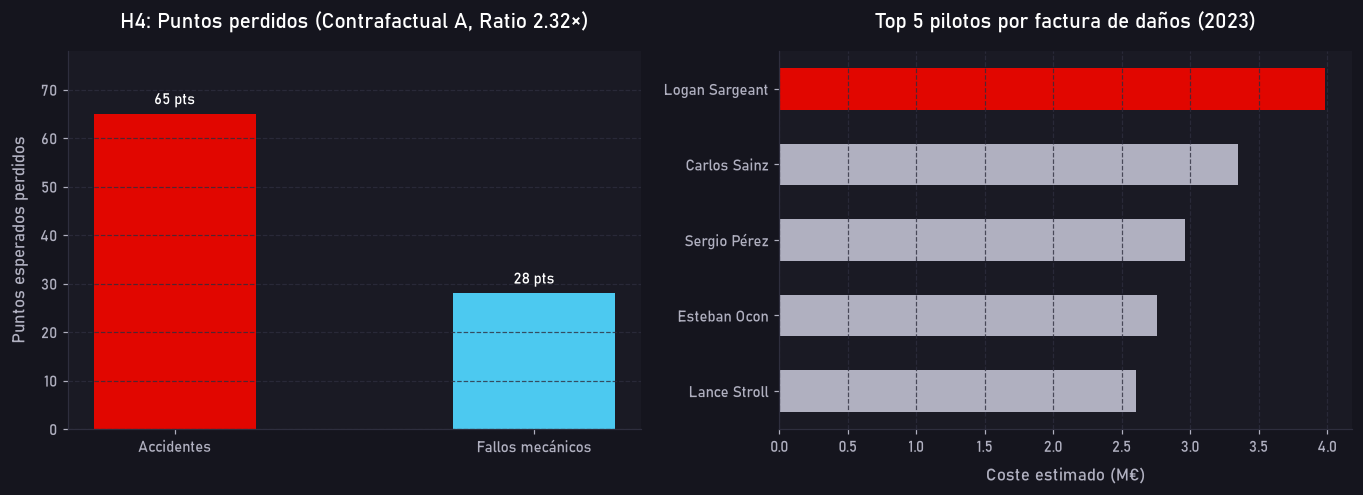

In [6]:
res_h4 = evaluar_h4(datos_23["results"], datos_23["lap_times"])
danos = datos_23["damage_cost"].sort_values("damage_cost_eur", ascending=False)

print(
    f"Contrafactual A: Accidentes {res_h4['puntos_A_accident']:.0f} pts "
    f"vs Mecánicos {res_h4['puntos_A_mecanico']:.0f} pts -> Ratio {res_h4['ratio_A']:.2f}x"
)
print(
    f"Contrafactual B: Accidentes {res_h4['puntos_B_accident']:.1f} pts "
    f"vs Mecánicos {res_h4['puntos_B_mecanico']:.1f} pts -> Ratio {res_h4['ratio_B']:.2f}x"
)
print(f"Factura total estimada de daños 2023: {danos['damage_cost_eur'].sum()/1e6:.2f} M€")
print(f"Veredicto H4: {'✅ CONFIRMADA' if res_h4['confirmada'] else '⚪ NO SE CONFIRMA'}")

with f1_dark_context():
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.6))

    cats = ["Accidentes", "Fallos mecánicos"]
    pts = [res_h4["puntos_A_accident"], res_h4["puntos_A_mecanico"]]
    b1 = ax1.bar(cats, pts, color=[ROJO_F1, AZUL_MEC], width=0.45)
    for bar, val in zip(b1, pts):
        ax1.text(bar.get_x() + bar.get_width() / 2, val + 2, f"{int(val)} pts", ha="center", color=BLANCO_F1, fontweight="bold")
    estilizar_ejes_f1(ax1, "H4: Puntos perdidos (Contrafactual A, Ratio 2.32×)", ylabel="Puntos esperados perdidos", grid_axis="y")
    ax1.set_ylim(0, 78)

    top5 = danos.head(5).iloc[::-1]
    col_top5 = [PLATA_F1] * 4 + [ROJO_F1]
    ax2.barh(top5["driver_name"], top5["damage_cost_eur"] / 1e6, color=col_top5, height=0.55)
    estilizar_ejes_f1(ax2, "Top 5 pilotos por factura de daños (2023)", "Coste estimado (M€)", grid_axis="x")

    plt.tight_layout()
    plt.show()

## 6. Tabla resumen de contraste de hipótesis

In [7]:
resumen = pd.DataFrame([
    {
        "Hipótesis": "H1 (1990–2023)",
        "Métrica principal": f"{res_h1['tasa_1990s']:.1f}% → {res_h1['tasa_2020s']:.1f}% (-{res_h1['reduccion_pct']:.0f}%)",
        "Umbral": "< 1/3 tasa 1990s",
        "Veredicto": "CONFIRMADA ✅" if res_h1["confirmada"] else "NO SE CONFIRMA ⚪",
    },
    {
        "Hipótesis": "H2 (1990–2023)",
        "Métrica principal": f"Cuota {res_h2['medias_cuota']['2020-2023']:.1%}, {res_h2['temporadas_sobre_50']}/4 temp. > 50%",
        "Umbral": ">= 3/4 temp. > 50%",
        "Veredicto": "CONFIRMADA ✅" if res_h2["confirmada"] else "NO SE CONFIRMA ⚪",
    },
    {
        "Hipótesis": "H3 (2023)",
        "Métrica principal": f"Top-3 {res_h3['top3_pct']:.1f}%, p={res_h3['p_value_chi2']:.4f}, grad {res_h3['gradiente_parrilla']:.2f}x",
        "Umbral": "Top3>=50%, p<0.05 y grad>=1.5x",
        "Veredicto": "CONFIRMADA ✅" if res_h3["confirmada"] else "NO SE CONFIRMA ⚪",
    },
    {
        "Hipótesis": "H4 (2023)",
        "Métrica principal": f"{res_h4['puntos_A_accident']:.0f} vs {res_h4['puntos_A_mecanico']:.0f} pts (Ratio {res_h4['ratio_A']:.2f}x)",
        "Umbral": "Ratio >= 1.5x",
        "Veredicto": "CONFIRMADA ✅" if res_h4["confirmada"] else "NO SE CONFIRMA ⚪",
    },
])
resumen

,Hipótesis,Métrica principal,Umbral,Veredicto
0,H1 (1990–2023),30.2% → 7.0% (-77%),< 1/3 tasa 1990s,CONFIRMADA ✅
1,H2 (1990–2023),"Cuota 52.6%, 2/4 temp. > 50%",>= 3/4 temp. > 50%,NO SE CONFIRMA ⚪
2,H3 (2023),"Top-3 48.5%, p=0.9661, grad 1.52x","Top3>=50%, p<0.05 y grad>=1.5x",NO SE CONFIRMA ⚪
3,H4 (2023),65 vs 28 pts (Ratio 2.32x),Ratio >= 1.5x,CONFIRMADA ✅
